# Radar's leverage: five echoes vs. two hundred telescope images

**Question.** Optical astrometry measures *direction*. Radar measures *distance* (round-trip
delay) and *line-of-sight speed* (Doppler) with a precision of ~150 m and ~mm/s. How much does a
handful of radar measurements improve the orbit of a near-Earth asteroid that was only followed
for a few months?

**Test case: 2017 BQ6.** A ~250 m Apollo asteroid discovered on 2017 Jan 26. It passed Earth
at 6.6 lunar distances twelve days later and Goldstone (DSS-14) ranged it on two nights. It was
then followed optically until June 2017, so it has a **single 130-day apparition**. That is
the regime where radar matters most.

PyRoOrb folds radar delay/Doppler rows into the final differential correction whenever the
observations carry them. `fetch_observations` pulls them from JPL's radar database into
`obs.meta["radar"]`. To see their leverage we fit twice, with and without radar.

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


In [2]:
desig = "2017 BQ6"
obs = pyroorb.fetch_observations(desig)
radar = obs.meta["radar"]
print(f"{len(obs)} optical observations, {len(radar)} radar measurements")

import pandas as pd
from astropy.time import Time
pd.DataFrame([{"UTC": Time(r["jd_utc"], format="jd").iso[:16], "kind": r["kind"],
               "value": r["value"], "sigma": r["sigma"],
               "unit": "s (round trip)" if r["kind"] == "delay" else "Hz"} for r in radar])

224 optical observations, 5 radar measurements


,UTC,kind,value,sigma,unit
0,2017-02-06 00:40,doppler,284941.837000,2.000000,Hz
1,2017-02-06 01:00,delay,18.570418,0.000010,s (round trip)
2,2017-02-06 01:10,delay,18.550759,0.000001,s (round trip)
3,2017-02-07 02:50,doppler,34144.502000,2.000000,Hz
4,2017-02-07 04:30,delay,16.803406,0.000002,s (round trip)


Each delay is a round-trip light time of ~17-19 s measured to 1-10 **micro**seconds, i.e. the
Earth-asteroid distance to ~150-1500 m. The Doppler shifts at 8.56 GHz carry 2 Hz sigmas,
i.e. the line-of-sight speed to ~3.5 cm/s.

## Two fits: optical only, and optical + radar

In [3]:
fit_radar = pyroorb.fit_orbit(obs, designation=desig)
optical_only = pyroorb.Observations(obs, {**obs.meta, "radar": []})   # same obs, radar removed
fit_opt = pyroorb.fit_orbit(optical_only, designation=desig)

for name, f in [("optical only", fit_opt), ("optical + radar", fit_radar)]:
    print(f"{name:16s} rms {f.rms_residual():.3f}\"  n_obs {f.n_observations()}  "
          f"arc {f.arc_length_days():.0f} d  U = {f.uncertainty_parameter():.1f}")
print("radar joint:", {k: v for k, v in fit_radar.radar.items() if k != "rows"})

(ASSIST) The JPL asteroid ephemeris file has not been found. Asteroid forces have been disabled.


optical only     rms 0.431"  n_obs 224  arc 130 d  U = 4.9
optical + radar  rms 0.442"  n_obs 224  arc 130 d  U = 3.2
radar joint: {'applied': True, 'n': 5, 'n_used': 5, 'pre_median_z': 16.568708871744775, 'post_median_z': 0.15956828391949784}


Both fits match the optical data equally well (rms ≈ 0.43-0.44″). Radar does not change how
well the orbit fits the *images*; it pins down a direction the images barely constrain.

## How wrong is the optical-only orbit along the line of sight?

We predict the radar measurements from the **optical-only** orbit and compare them with the
residuals of the joint fit. (This step uses PyRoOrb's internal radar model, `pyroorb.radar`:
an internal API that may change.)

In [4]:
from pyroorb import radar as radar_model

rctx = radar_model.radar_context(radar, pyroorb.obscodes())
ctx = fit_opt._ctx
states = ctx["backend"].helio_states_multi(ctx["epoch_tdb"], [np.asarray(fit_opt._state, float)],
                                           rctx["t_tdb"], nongrav=None)
z_opt = radar_model.radar_residuals(states, rctx)[:, 0]          # (O-C)/sigma, optical-only orbit
z_joint = [row["z"] for row in fit_radar.radar["rows"]]          # (O-C)/sigma after the joint fit

C_KM_S = 299792.458
rows = []
for r, zo, zj in zip(radar, z_opt, z_joint):
    o_c = zo * r["sigma"]
    phys = (f"{o_c * 1e6:+8.1f} us  = {o_c * C_KM_S / 2:+6.1f} km in range" if r["kind"] == "delay"
            else f"{o_c:+8.2f} Hz  = {o_c * C_KM_S * 1e5 / (2 * r['freq_hz']):+6.2f} cm/s")
    rows.append({"kind": r["kind"], "optical-only O-C": phys,
                 "optical-only (sigma)": round(zo, 1), "joint fit (sigma)": round(zj, 2)})
pd.DataFrame(rows)

,kind,optical-only O-C,optical-only (sigma),joint fit (sigma)
0,doppler,+0.49 Hz = +0.87 cm/s,0.2,0.06
1,delay,-165.7 us = -24.8 km in range,-16.6,-0.29
2,delay,-162.7 us = -24.4 km in range,-162.7,0.16
3,doppler,+0.84 Hz = +1.47 cm/s,0.4,-0.09
4,delay,-172.0 us = -25.8 km in range,-114.7,-0.21


The optical-only orbit already predicts the **Doppler** (the radial *velocity*) to within its
2 Hz sigma. But it puts the asteroid about **25 km** off in *distance*, which is 16-160σ for
the delay measurements. After the joint fit every radar row sits well inside 1σ, while the
optical rms is unchanged.

## What that buys: element uncertainties, and JPL's for reference

In [5]:
import json, urllib.request
sb = json.load(urllib.request.urlopen(
    "https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=2017%20BQ6", timeout=30))["orbit"]
jpl = {e["name"]: float(e["sigma"]) for e in sb["elements"]}
print(f"JPL solution {sb['orbit_id']}: {sb['n_obs_used']} optical + {sb['n_del_obs_used']} delay "
      f"+ {sb['n_dop_obs_used']} Doppler, arc {sb['data_arc']} d")

so, sr = fit_opt.element_sigmas(), fit_radar.element_sigmas()
pd.DataFrame([{"element": k, "optical only": so[k], "optical + radar": sr[k],
               "improvement": round(so[k] / sr[k], 1), "JPL (with radar)": jpl.get(j)}
              for k, j in [("a", "a"), ("e", "e"), ("q", "q"), ("i", "i"), ("asc_node", "om"),
                           ("arg_per", "w")]]).set_index("element")

JPL solution 29: 229 optical + 3 delay + 2 Doppler, arc 130 d


,optical only,optical + radar,improvement,JPL (with radar)
element,,,,
a,2.675759e-05,2.186643e-06,12.2,6.700000e-06
e,6.895827e-06,5.502484e-07,12.5,1.800000e-06
q,8.400173e-07,9.882179e-08,8.5,3.900000e-07
i,1.011467e-04,1.015916e-05,10.0,1.400000e-05
asc_node,1.894381e-05,5.241735e-06,3.6,6.700000e-06
arg_per,7.586456e-05,2.316776e-05,3.3,2.300000e-05


Five radar numbers shrink the 1σ of a, e, q, i by **~10×** (the orientation angles Ω and ω
by ~3×): the kind of gain that otherwise takes years of extra optical coverage, bought in
two nights. (JPL's elements refer to a 2026 epoch rather than our 2017 one, so its M and Tp
sigmas, which grow with time from the data, are not comparable and are left out.)

## ...and where to point a telescope at the next apparitions

The practical payoff is the sky-plane uncertainty of future predictions. We compare PyRoOrb's
1σ ellipse semi-major axis with JPL Horizons' own (Horizons quotes 3σ; we divide by 3).

median improvement from radar: x12.2
median PyRoOrb(radar) / JPL: 0.32


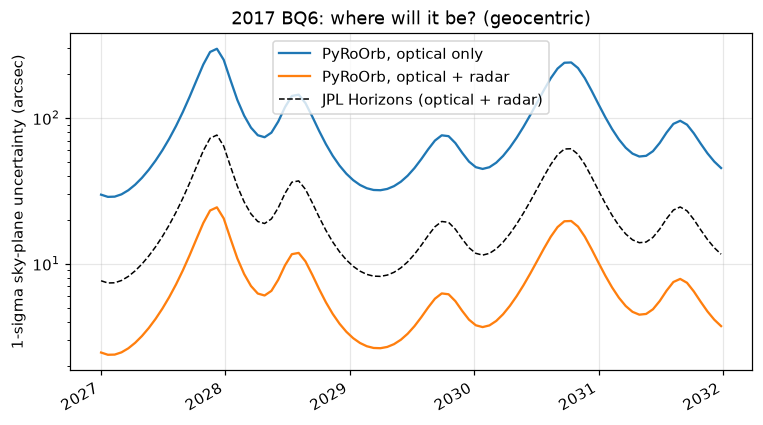

In [6]:
start, stop, step = "2027-01-01", "2032-01-01", 20
eph_opt = pyroorb.ephemeris(fit_opt, start, stop, step=step, site="500")
eph_rad = pyroorb.ephemeris(fit_radar, start, stop, step=step, site="500")
t = Time([e["jd_utc"] for e in eph_rad], format="jd").datetime

import urllib.parse
q = {"format": "json", "COMMAND": "'DES=2017 BQ6;'", "EPHEM_TYPE": "OBSERVER", "CENTER": "'500@399'",
     "START_TIME": f"'{start}'", "STOP_TIME": f"'{stop}'", "STEP_SIZE": f"'{step} d'",
     "QUANTITIES": "'37'", "OBJ_DATA": "NO"}
res = json.load(urllib.request.urlopen(
    "https://ssd.jpl.nasa.gov/api/horizons.api?" + urllib.parse.urlencode(q), timeout=60))["result"]
lines = res[res.index("$$SOE") + 5:res.index("$$EOE")].strip().splitlines()
jpl_smaa = np.array([float(l.split()[2]) for l in lines]) / 3.0       # 3-sigma -> 1-sigma

fig, ax = plt.subplots()
ax.semilogy(t, [e["unc_smaj_arcsec"] for e in eph_opt], label="PyRoOrb, optical only")
ax.semilogy(t, [e["unc_smaj_arcsec"] for e in eph_rad], label="PyRoOrb, optical + radar")
ax.semilogy(t[:len(jpl_smaa)], jpl_smaa, "k--", lw=1, label="JPL Horizons (optical + radar)")
ax.set_ylabel("1-sigma sky-plane uncertainty (arcsec)")
ax.set_title("2017 BQ6: where will it be? (geocentric)")
ax.legend()
fig.autofmt_xdate()
ratio = np.median([a["unc_smaj_arcsec"] / b["unc_smaj_arcsec"] for a, b in zip(eph_opt, eph_rad)])
print(f"median improvement from radar: x{ratio:.1f}")
print(f"median PyRoOrb(radar) / JPL: {np.median(np.array([e['unc_smaj_arcsec'] for e in eph_rad])[:len(jpl_smaa)] / jpl_smaa):.2f}")

## Takeaways

* Five radar measurements from two nights shrink the 1σ uncertainties of a, e, q, i and of
  the predicted sky position by roughly **10×**. The images fixed the asteroid's direction and radial velocity; radar fixed
  its distance, which a 130-day arc had left ~25 km off.
* The improvement is the same *shape* as JPL's: PyRoOrb's radar-constrained prediction tracks
  the Horizons uncertainty curve through the 2027-2031 apparitions.

**Caveat (honest comparison).** PyRoOrb's radar-constrained 1σ ellipse is about **3× smaller**
than JPL's, and JPL's sigma on `a` is likewise ~3× larger than ours. Both use essentially the
same data. The difference comes from the observation weighting and error model (JPL weights
the optical data more conservatively), not from the radar. The *ratio* with/without radar
within one code is the robust number here. Absolute uncertainties should be compared with
care.